In [15]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Set seeds for scientific reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {DEVICE}")

# Grid & Vocabulary Configuration
GRID_SIZE = 8          # 8x8 Maze Grid
WALL_PROB = 0.5       # Probability of a cell being an obstacle

# Maze Input Vocab: 0=Free, 1=Wall, 2=Start, 3=Goal
MAZE_VOCAB = {"FREE": 0, "WALL": 1, "START": 2, "GOAL": 3}

# Action Output Vocab: PAD, BOS, EOS, and directional moves U, L, R, D
ACTION_VOCAB = {"PAD": 0, "BOS": 1, "EOS": 2, "U": 3, "L": 4, "R": 5, "D": 6}
IDX_TO_ACTION = {v: k for k, v in ACTION_VOCAB.items()}

# Coordinate deltas corresponding to U, L, R, D
MOVE_DELTAS = {
    "U": (-1, 0),
    "L": (0, -1),
    "R": (0, 1),
    "D": (1, 0)
}



Running on device: cuda


In [16]:
def generate_solvable_maze(size=GRID_SIZE, wall_prob=WALL_PROB, min_path_len=4):
    """
    Generates a random 2D grid maze and uses Breadth-First Search (BFS)
    to guarantee a valid shortest path of (U, L, R, D) actions exists.
    """
    while True:
        # 1. Initialize random walls and free spaces
        grid = np.random.choice(
            [MAZE_VOCAB["FREE"], MAZE_VOCAB["WALL"]],
            size=(size, size),
            p=[1 - wall_prob, wall_prob]
        )

        # 2. Pick distinct random coordinates for Start and Goal
        start = (random.randint(0, size - 1), random.randint(0, size - 1))
        goal = (random.randint(0, size - 1), random.randint(0, size - 1))
        if start == goal:
            continue

        grid[start] = MAZE_VOCAB["START"]
        grid[goal] = MAZE_VOCAB["GOAL"]

        # 3. Breadth-First Search (BFS) for shortest action sequence
        queue = deque([(start[0], start[1], [])])
        visited = {start}

        while queue:
            r, c, path = queue.popleft()
            if (r, c) == goal:
                if len(path) >= min_path_len:
                    return grid, path, start, goal
                break

            # Explore neighbors in canonical order: U, L, R, D
            for action, (dr, dc) in MOVE_DELTAS.items():
                nr, nc = r + dr, c + dc
                if 0 <= nr < size and 0 <= nc < size:
                    if grid[nr, nc] != MAZE_VOCAB["WALL"] and (nr, nc) not in visited:
                        visited.add((nr, nc))
                        queue.append((nr, nc, path + [action]))


class MazeDataset(Dataset):
    def __init__(self, num_samples=12000, size=GRID_SIZE):
        self.samples = []
        self.max_seq_len = size * size  # Upper bound on path length

        print(f"Generating {num_samples} solvable mazes via BFS...")
        for _ in range(num_samples):
            grid, path, start, goal = generate_solvable_maze(size=size)
            # Tokenize action sequence: [BOS, ...actions..., EOS]
            seq = [ACTION_VOCAB["BOS"]] + [ACTION_VOCAB[a] for a in path] + [ACTION_VOCAB["EOS"]]
            self.samples.append((grid, seq))

        self.max_len = max(len(s[1]) for s in self.samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        grid, seq = self.samples[idx]
        # Pad sequence to uniform length for batch processing
        padded_seq = seq + [ACTION_VOCAB["PAD"]] * (self.max_len - len(seq))
        return (
            torch.tensor(grid, dtype=torch.long),
            torch.tensor(padded_seq, dtype=torch.long)
        )


# Create Training & Validation Datasets
train_dataset = MazeDataset(num_samples=50000)
val_dataset = MazeDataset(num_samples=5000)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)


Generating 50000 solvable mazes via BFS...
Generating 5000 solvable mazes via BFS...


In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RoPE2DEncoderLayer(nn.Module):
    """
    Applies 2D RoPE strictly to Q and K inside self-attention at every layer.
    """
    def __init__(self, d_model, nhead, dim_feedforward, dropout, rope_cos, rope_sin):
        super().__init__()
        self.nhead = nhead
        self.head_dim = d_model // nhead

        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model),
            nn.Dropout(dropout)
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer("cos", rope_cos, persistent=False)
        self.register_buffer("sin", rope_sin, persistent=False)

    @staticmethod
    def _rotate_qk(x, cos, sin):
        x_rot = torch.stack([-x[..., 1::2], x[..., ::2]], dim=-1).flatten(-2)
        return (x * cos) + (x_rot * sin)

    def forward(self, src):
        B, S, D = src.shape

        # 1. Project Q, K, V -> (B, nhead, H*W, head_dim)
        q, k, v = self.qkv(src).chunk(3, dim=-1)
        q = q.view(B, S, self.nhead, self.head_dim).transpose(1, 2)
        k = k.view(B, S, self.nhead, self.head_dim).transpose(1, 2)
        v = v.view(B, S, self.nhead, self.head_dim).transpose(1, 2)

        # 2. Apply 2D RoPE strictly to Q and K
        q = self._rotate_qk(q, self.cos, self.sin)
        k = self._rotate_qk(k, self.cos, self.sin)

        # 3. Flash / Scaled Dot-Product Attention
        attn = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.dropout.p if self.training else 0.0
        )
        attn = self.out_proj(attn.transpose(1, 2).contiguous().view(B, S, D))

        # 4. Residual + FFN
        src = self.norm1(src + self.dropout(attn))
        src = self.norm2(src + self.ffn(src))
        return src


class MazeTransformerSolver(nn.Module):
    def __init__(
        self,
        grid_size=GRID_SIZE,
        d_model=128,
        nhead=8,
        num_layers=4,
        dim_feedforward=256,
        dropout=0.1,
        max_seq_len=64
    ):
        super().__init__()
        self.grid_size = grid_size
        self.d_model = d_model
        head_dim = d_model // nhead  # 16 (divisible by 4)

        # 1. Precompute 2D RoPE cache at the HEAD dimension: (1, 1, H*W, head_dim)
        half_hd = head_dim // 2
        inv_freq = 1.0 / (1000.0 ** (torch.arange(0, half_hd, 2).float() / half_hd))
        rows = torch.arange(grid_size).repeat_interleave(grid_size).float()
        cols = torch.arange(grid_size).repeat(grid_size).float()
        angles = torch.cat([
            torch.outer(rows, inv_freq).repeat_interleave(2, dim=-1),
            torch.outer(cols, inv_freq).repeat_interleave(2, dim=-1)
        ], dim=-1)[None, None, :, :]  # (1, 1, H*W, head_dim)
        rope_cos, rope_sin = angles.cos(), angles.sin()

        # 2. Embeddings
        self.maze_token_emb = nn.Embedding(len(MAZE_VOCAB), d_model)
        self.action_token_emb = nn.Embedding(len(ACTION_VOCAB), d_model)
        self.pos_emb = nn.Embedding(max_seq_len, d_model)

        # 3. Encoder Stack (Using ModuleList avoids PyTorch's .self_attn check!)
        self.encoder_layers = nn.ModuleList([
            RoPE2DEncoderLayer(d_model, nhead, dim_feedforward, dropout, rope_cos, rope_sin)
            for _ in range(num_layers)
        ])
        self.encoder_norm = nn.LayerNorm(d_model)

        # Also save a (1, H*W, d_model) 2D RoPE buffer to tag `memory` for Decoder Cross-Attention
        self.register_buffer("mem_cos", rope_cos.squeeze(0).repeat(1, 1, nhead), persistent=False)
        self.register_buffer("mem_sin", rope_sin.squeeze(0).repeat(1, 1, nhead), persistent=False)

        # 4. Standard PyTorch Transformer Decoder
        dec_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.decoder = nn.TransformerDecoder(dec_layer, num_layers=num_layers, norm=nn.LayerNorm(d_model))

        self.fc_out = nn.Linear(d_model, len(ACTION_VOCAB))

    def encode_maze(self, grid):
        B = grid.size(0)
        src = self.maze_token_emb(grid.view(B, -1))

        # Pass through 2D-RoPE Encoder layers
        for layer in self.encoder_layers:
            src = layer(src)
        src = self.encoder_norm(src)

        # Rotate final encoder memory so Decoder Cross-Attention Keys also have 2D (r, c) coordinates
        return RoPE2DEncoderLayer._rotate_qk(src, self.mem_cos, self.mem_sin)

    def forward(self, grid, tgt_seq):
        B, T = tgt_seq.shape
        memory = self.encode_maze(grid)

        positions = torch.arange(0, T, device=tgt_seq.device).unsqueeze(0)
        tgt = self.action_token_emb(tgt_seq) + self.pos_emb(positions)

        causal_mask = torch.triu(
            torch.ones(T, T, device=tgt_seq.device, dtype=torch.bool), diagonal=1
        )
        tgt_pad_mask = (tgt_seq == ACTION_VOCAB["PAD"])

        out = self.decoder(
            tgt=tgt,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=tgt_pad_mask
        )
        return self.fc_out(out)

In [18]:
model = MazeTransformerSolver().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=ACTION_VOCAB["PAD"])

EPOCHS = 10

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0

    for grids, seqs in train_loader:
        grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)

        # Teacher Forcing: Input is [BOS, a_1, ..., a_T], Target is [a_1, ..., a_T, EOS]
        tgt_input = seqs[:, :-1]
        tgt_labels = seqs[:, 1:]

        optimizer.zero_grad()
        logits = model(grids, tgt_input)

        loss = criterion(logits.reshape(-1, len(ACTION_VOCAB)), tgt_labels.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

    # Calculate validation token accuracy
    model.eval()
    correct_tokens, total_tokens = 0, 0
    with torch.no_grad():
        for grids, seqs in val_loader:
            grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)
            tgt_input, tgt_labels = seqs[:, :-1], seqs[:, 1:]
            logits = model(grids, tgt_input)
            preds = logits.argmax(dim=-1)
            mask = tgt_labels != ACTION_VOCAB["PAD"]
            correct_tokens += (preds[mask] == tgt_labels[mask]).sum().item()
            total_tokens += mask.sum().item()

    val_acc = (correct_tokens / total_tokens) * 100
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {total_loss/len(train_loader):.4f} | Val Token Acc: {val_acc:.2f}%")


Epoch 01/10 | Train Loss: 0.8373 | Val Token Acc: 73.42%
Epoch 02/10 | Train Loss: 0.5352 | Val Token Acc: 84.78%
Epoch 03/10 | Train Loss: 0.2976 | Val Token Acc: 93.74%
Epoch 04/10 | Train Loss: 0.1907 | Val Token Acc: 96.29%
Epoch 05/10 | Train Loss: 0.1411 | Val Token Acc: 97.12%
Epoch 06/10 | Train Loss: 0.1133 | Val Token Acc: 98.45%
Epoch 07/10 | Train Loss: 0.0935 | Val Token Acc: 98.37%
Epoch 08/10 | Train Loss: 0.0787 | Val Token Acc: 98.42%
Epoch 09/10 | Train Loss: 0.0701 | Val Token Acc: 98.70%
Epoch 10/10 | Train Loss: 0.0651 | Val Token Acc: 98.91%


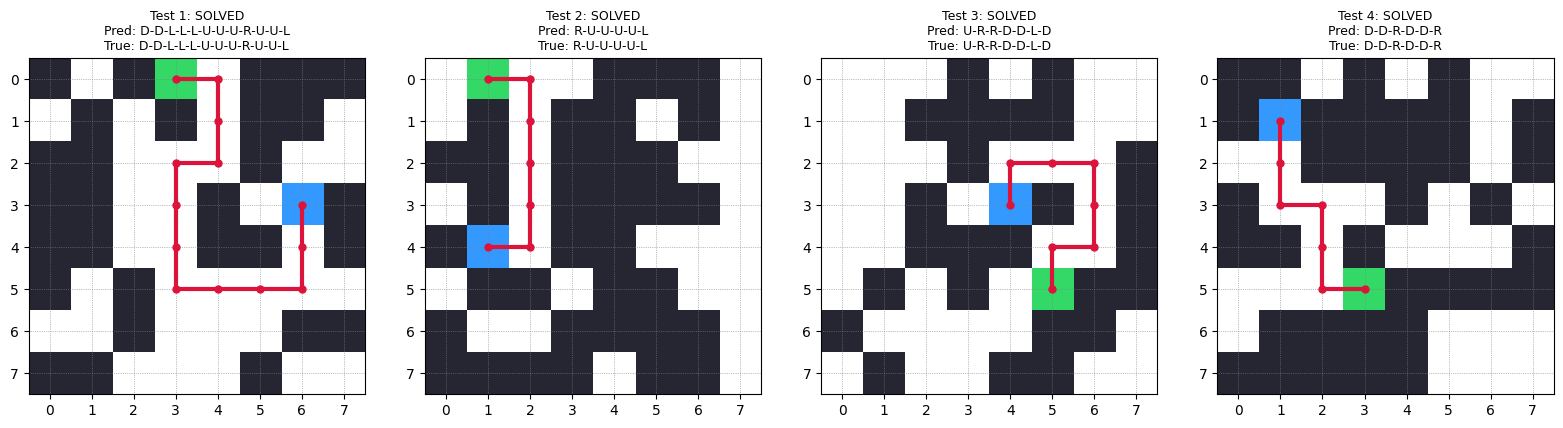

In [21]:
@torch.no_grad()
def solve_maze_autoregressive(model, grid, max_steps=40):
    """
    Takes a raw 2D maze grid and autoregressively predicts ['U', 'L', 'R', 'D']
    one token at a time until EOS is emitted.
    """
    model.eval()
    grid_tensor = torch.tensor(grid, dtype=torch.long, device=DEVICE).unsqueeze(0)
    memory = model.encode_maze(grid_tensor)

    generated = [ACTION_VOCAB["BOS"]]

    for _ in range(max_steps):
        tgt_seq = torch.tensor([generated], dtype=torch.long, device=DEVICE)
        T = tgt_seq.size(1)
        positions = torch.arange(0, T, device=DEVICE).unsqueeze(0)

        tgt = model.action_token_emb(tgt_seq) + model.pos_emb(positions)
        causal_mask = torch.triu(torch.ones(T, T, device=DEVICE, dtype=torch.bool), diagonal=1)

        # Fixed: Use model.decoder instead of model.transformer.decoder
        out = model.decoder(tgt=tgt, memory=memory, tgt_mask=causal_mask)
        next_token_logits = model.fc_out(out[:, -1, :])
        next_token = next_token_logits.argmax(dim=-1).item()

        if next_token == ACTION_VOCAB["EOS"]:
            break
        generated.append(next_token)

    return [IDX_TO_ACTION[idx] for idx in generated[1:]]


def visualize_predictions(model, num_tests=4):
    # Fixed: 4 * num_tests
    fig, axes = plt.subplots(1, num_tests, figsize=(4 * num_tests, 4))
    if num_tests == 1:
        axes = [axes]

    for idx, ax in enumerate(axes):
        grid, true_path, start, goal = generate_solvable_maze()
        pred_actions = solve_maze_autoregressive(model, grid)

        # Trace predicted path coordinates
        curr_r, curr_c = start
        path_coords = [(curr_r, curr_c)]
        valid_trace = True

        for act in pred_actions:
            if act not in MOVE_DELTAS:
                continue
            dr, dc = MOVE_DELTAS[act]
            nr, nc = curr_r + dr, curr_c + dc
            if 0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE and grid[nr, nc] != MAZE_VOCAB["WALL"]:
                curr_r, curr_c = nr, nc
                path_coords.append((curr_r, curr_c))
            else:
                valid_trace = False
                break

        reached_goal = (curr_r, curr_c) == goal and valid_trace

        # Render grid colors
        color_map = np.ones((GRID_SIZE, GRID_SIZE, 3))
        color_map[grid == MAZE_VOCAB["WALL"]] = [0.15, 0.15, 0.2]   # Dark Slate Walls
        color_map[start] = [0.2, 0.6, 1.0]                          # Blue Start
        color_map[goal] = [0.2, 0.85, 0.4]                          # Green Goal

        ax.imshow(color_map)

        # Plot predicted trajectory line
        ys = [c for r, c in path_coords]
        xs = [r for r, c in path_coords]
        ax.plot(ys, xs, color="crimson", linewidth=3, marker="o", markersize=5, label="Pred Path")

        status = "SOLVED" if reached_goal else "FAILED"
        ax.set_title(
            f"Test {idx+1}: {status}\nPred: {'-'.join(pred_actions)}\nTrue: {'-'.join(true_path)}",
            fontsize=9
        )
        ax.set_xticks(range(GRID_SIZE))
        ax.set_yticks(range(GRID_SIZE))
        ax.grid(color="gray", linestyle=":", linewidth=0.5)

    plt.tight_layout()
    plt.show()

# Run visual evaluation on 4 unseen mazes
visualize_predictions(model, num_tests=4)

In [2]:
import random
from collections import deque, defaultdict
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, Sampler

# Ensure vocabularies and move deltas are defined
MAZE_VOCAB = {"FREE": 0, "WALL": 1, "START": 2, "GOAL": 3}
ACTION_VOCAB = {"PAD": 0, "BOS": 1, "EOS": 2, "U": 3, "L": 4, "R": 5, "D": 6}
IDX_TO_ACTION = {v: k for k, v in ACTION_VOCAB.items()}
MOVE_DELTAS = {"U": (-1, 0), "L": (0, -1), "R": (0, 1), "D": (1, 0)}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class DynamicRoPE2DEncoderLayer(nn.Module):
    """
    Applies dynamically computed 2D RoPE (cos, sin) to Q and K for ANY grid size (H, W).
    """
    def __init__(self, d_model, nhead, dim_feedforward, dropout):
        super().__init__()
        self.nhead = nhead
        self.head_dim = d_model // nhead

        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model),
            nn.Dropout(dropout)
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    @staticmethod
    def rotate_qk(x, cos, sin):
        x_rot = torch.stack([-x[..., 1::2], x[..., ::2]], dim=-1).flatten(-2)
        return (x * cos) + (x_rot * sin)

    def forward(self, src, rope_cos, rope_sin):
        B, S, D = src.shape

        # 1. Project Q, K, V -> (B, nhead, H*W, head_dim)
        q, k, v = self.qkv(src).chunk(3, dim=-1)
        q = q.view(B, S, self.nhead, self.head_dim).transpose(1, 2)
        k = k.view(B, S, self.nhead, self.head_dim).transpose(1, 2)
        v = v.view(B, S, self.nhead, self.head_dim).transpose(1, 2)

        # 2. Apply dynamic 2D RoPE to Q and K
        q = self.rotate_qk(q, rope_cos, rope_sin)
        k = self.rotate_qk(k, rope_cos, rope_sin)

        # 3. Scaled Dot-Product Attention
        attn = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.dropout.p if self.training else 0.0
        )
        attn = self.out_proj(attn.transpose(1, 2).contiguous().view(B, S, D))

        # 4. Residual + FFN
        src = self.norm1(src + self.dropout(attn))
        src = self.norm2(src + self.ffn(src))
        return src


class MazeTransformerSolver(nn.Module):
    """
    Resolution-agnostic Maze Transformer with Dynamic 2D RoPE in the Encoder
    and Continuous Sinusoidal 1D Embeddings in the Decoder for length extrapolation.
    """
    def __init__(
        self,
        d_model=128,
        nhead=8,
        num_layers=4,
        dim_feedforward=256,
        dropout=0.1
    ):
        super().__init__()
        self.d_model = d_model
        self.nhead = nhead
        self.head_dim = d_model // nhead
        assert self.head_dim % 4 == 0, "head_dim must be divisible by 4 for 2D RoPE"

        # 1. Store ONLY inverse frequencies (allows any HxW grid size at runtime!)
        half_hd = self.head_dim // 2
        inv_freq_2d = 1.0 / (10000.0 ** (torch.arange(0, half_hd, 2).float() / half_hd))
        self.register_buffer("inv_freq_2d", inv_freq_2d, persistent=False)

        # 1D frequency schedule for continuous decoder step positions (extrapolates to any T)
        inv_freq_1d = 1.0 / (10000.0 ** (torch.arange(0, d_model, 2).float() / d_model))
        self.register_buffer("inv_freq_1d", inv_freq_1d, persistent=False)

        # 2. Token Embeddings
        self.maze_token_emb = nn.Embedding(len(MAZE_VOCAB), d_model)
        self.action_token_emb = nn.Embedding(len(ACTION_VOCAB), d_model)

        # 3. Dynamic 2D-RoPE Encoder Stack
        self.encoder_layers = nn.ModuleList([
            DynamicRoPE2DEncoderLayer(d_model, nhead, dim_feedforward, dropout)
            for _ in range(num_layers)
        ])
        self.encoder_norm = nn.LayerNorm(d_model)

        # 4. Standard Transformer Decoder
        dec_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.decoder = nn.TransformerDecoder(
            dec_layer, num_layers=num_layers, norm=nn.LayerNorm(d_model)
        )
        self.fc_out = nn.Linear(d_model, len(ACTION_VOCAB))

    def _get_2d_rope(self, H: int, W: int, device: torch.device):
        """ Dynamically builds (1, 1, H*W, head_dim) 2D RoPE caches for any HxW grid. """
        rows = torch.arange(H, device=device, dtype=torch.float32).repeat_interleave(W)
        cols = torch.arange(W, device=device, dtype=torch.float32).repeat(H)

        angles = torch.cat([
            torch.outer(rows, self.inv_freq_2d).repeat_interleave(2, dim=-1),
            torch.outer(cols, self.inv_freq_2d).repeat_interleave(2, dim=-1)
        ], dim=-1)[None, None, :, :]  # (1, 1, H*W, head_dim)

        return angles.cos(), angles.sin()

    def _get_1d_sinusoidal_pos(self, T: int, device: torch.device):
        """ Dynamically builds (1, T, d_model) continuous sinusoidal position encodings. """
        pos = torch.arange(T, device=device, dtype=torch.float32)
        angles = torch.outer(pos, self.inv_freq_1d)
        pos_emb = torch.cat([angles.sin(), angles.cos()], dim=-1).unsqueeze(0)  # (1, T, d_model)
        return pos_emb

    def encode_maze(self, grid):
        B, H, W = grid.shape
        src = self.maze_token_emb(grid.view(B, -1))

        # Dynamically compute 2D RoPE for current (H, W)
        rope_cos, rope_sin = self._get_2d_rope(H, W, grid.device)

        for layer in self.encoder_layers:
            src = layer(src, rope_cos, rope_sin)
        src = self.encoder_norm(src)

        # Tag encoder memory with 2D coordinates for Decoder Cross-Attention
        mem_cos = rope_cos.squeeze(0).repeat(1, 1, self.nhead)
        mem_sin = rope_sin.squeeze(0).repeat(1, 1, self.nhead)
        return DynamicRoPE2DEncoderLayer.rotate_qk(src, mem_cos, mem_sin)

    def forward(self, grid, tgt_seq):
        B, T = tgt_seq.shape
        memory = self.encode_maze(grid)

        # Continuous 1D sinusoidal position encoding (extrapolates beyond training lengths!)
        tgt = self.action_token_emb(tgt_seq) + self._get_1d_sinusoidal_pos(T, tgt_seq.device)

        causal_mask = torch.triu(
            torch.ones(T, T, device=tgt_seq.device, dtype=torch.bool), diagonal=1
        )
        tgt_pad_mask = (tgt_seq == ACTION_VOCAB["PAD"])

        out = self.decoder(
            tgt=tgt,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=tgt_pad_mask
        )
        return self.fc_out(out)

In [3]:
def generate_solvable_maze(size=6, wall_prob=0.25, min_path_len=3, max_tries=500):
    """
    Generates a random (size x size) maze with wall density `wall_prob` and returns
    (grid, shortest_path, start, goal).
    """
    for _ in range(max_tries):
        grid = np.random.choice(
            [MAZE_VOCAB["FREE"], MAZE_VOCAB["WALL"]],
            size=(size, size),
            p=[1.0 - wall_prob, wall_prob]
        )
        start = (random.randint(0, size - 1), random.randint(0, size - 1))
        goal = (random.randint(0, size - 1), random.randint(0, size - 1))
        if start == goal:
            continue

        grid[start] = MAZE_VOCAB["START"]
        grid[goal] = MAZE_VOCAB["GOAL"]

        queue = deque([(start[0], start[1], [])])
        visited = {start}

        while queue:
            r, c, path = queue.popleft()
            if (r, c) == goal:
                if len(path) >= min_path_len:
                    return grid, path, start, goal
                break

            for action, (dr, dc) in MOVE_DELTAS.items():
                nr, nc = r + dr, c + dc
                if 0 <= nr < size and 0 <= nc < size:
                    if grid[nr, nc] != MAZE_VOCAB["WALL"] and (nr, nc) not in visited:
                        visited.add((nr, nc))
                        queue.append((nr, nc, path + [action]))
    # Fallback to slightly lower wall_prob if high density deadlocks
    return generate_solvable_maze(size=size, wall_prob=max(0.1, wall_prob - 0.1), min_path_len=min_path_len)


class MultiConfigMazeLoader:
    """
    Generates datasets across multiple (grid_size, wall_prob) combinations and yields
    shuffled mini-batches where each batch shares a uniform grid_size.
    """
    def __init__(self, grid_sizes, wall_probs, samples_per_config=3000, batch_size=128):
        self.batch_size = batch_size
        self.buckets = defaultdict(list)  # grid_size -> list of (grid_tensor, padded_seq_tensor)

        print(f"Generating Multi-Grid Dataset across sizes={grid_sizes}, p={wall_probs}...")
        for size in grid_sizes:
            raw_samples = []
            for p in wall_probs:
                for _ in range(samples_per_config):
                    grid, path, _, _ = generate_solvable_maze(size=size, wall_prob=p)
                    seq = [ACTION_VOCAB["BOS"]] + [ACTION_VOCAB[a] for a in path] + [ACTION_VOCAB["EOS"]]
                    raw_samples.append((grid, seq))

            max_len = max(len(s[1]) for s in raw_samples)
            for grid, seq in raw_samples:
                padded = seq + [ACTION_VOCAB["PAD"]] * (max_len - len(seq))
                self.buckets[size].append((
                    torch.tensor(grid, dtype=torch.long),
                    torch.tensor(padded, dtype=torch.long)
                ))
            print(f"  -> Size {size}x{size}: {len(self.buckets[size])} mazes (max seq len: {max_len})")

    def __iter__(self):
        all_batches = []
        for size, items in self.buckets.items():
            random.shuffle(items)
            for i in range(0, len(items), self.batch_size):
                chunk = items[i:i + self.batch_size]
                grids = torch.stack([c[0] for c in chunk])
                seqs = torch.stack([c[1] for c in chunk])
                all_batches.append((grids, seqs))
        random.shuffle(all_batches)
        return iter(all_batches)

    def __len__(self):
        return sum((len(items) + self.batch_size - 1) // self.batch_size for items in self.buckets.values())


# ==========================================
# Train on Multiple Grid Sizes & Wall Probs
# ==========================================
TRAIN_SIZES = [5, 6, 7]
TRAIN_WALL_PROBS = [0.15, 0.25, 0.35]

train_loader = MultiConfigMazeLoader(
    grid_sizes=TRAIN_SIZES,
    wall_probs=TRAIN_WALL_PROBS,
    samples_per_config=4000,  # 3 sizes * 3 probs * 4000 = 36,000 training mazes
    batch_size=128
)
val_loader = MultiConfigMazeLoader(
    grid_sizes=TRAIN_SIZES,
    wall_probs=TRAIN_WALL_PROBS,
    samples_per_config=400,   # 3,600 validation mazes
    batch_size=128
)

model = MazeTransformerSolver(d_model=128, nhead=8, num_layers=4).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=ACTION_VOCAB["PAD"])

EPOCHS = 25

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0

    for grids, seqs in train_loader:
        grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)
        tgt_input, tgt_labels = seqs[:, :-1], seqs[:, 1:]

        optimizer.zero_grad()
        logits = model(grids, tgt_input)
        loss = criterion(logits.reshape(-1, len(ACTION_VOCAB)), tgt_labels.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

    # Validation Token Accuracy across all training grid sizes
    model.eval()
    correct_tokens, total_tokens = 0, 0
    with torch.no_grad():
        for grids, seqs in val_loader:
            grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)
            tgt_input, tgt_labels = seqs[:, :-1], seqs[:, 1:]
            logits = model(grids, tgt_input)
            preds = logits.argmax(dim=-1)
            mask = tgt_labels != ACTION_VOCAB["PAD"]
            correct_tokens += (preds[mask] == tgt_labels[mask]).sum().item()
            total_tokens += mask.sum().item()

    val_acc = (correct_tokens / total_tokens) * 100
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {total_loss/len(train_loader):.4f} | Val Token Acc: {val_acc:.2f}%")

Generating Multi-Grid Dataset across sizes=[5, 6, 7], p=[0.15, 0.25, 0.35]...
  -> Size 5x5: 12000 mazes (max seq len: 16)
  -> Size 6x6: 12000 mazes (max seq len: 20)
  -> Size 7x7: 12000 mazes (max seq len: 23)
Generating Multi-Grid Dataset across sizes=[5, 6, 7], p=[0.15, 0.25, 0.35]...
  -> Size 5x5: 1200 mazes (max seq len: 13)
  -> Size 6x6: 1200 mazes (max seq len: 17)
  -> Size 7x7: 1200 mazes (max seq len: 21)
Epoch 01/25 | Train Loss: 0.7841 | Val Token Acc: 82.85%
Epoch 02/25 | Train Loss: 0.3381 | Val Token Acc: 93.09%
Epoch 03/25 | Train Loss: 0.2126 | Val Token Acc: 94.76%
Epoch 04/25 | Train Loss: 0.1700 | Val Token Acc: 95.56%
Epoch 05/25 | Train Loss: 0.1403 | Val Token Acc: 96.91%
Epoch 06/25 | Train Loss: 0.1239 | Val Token Acc: 96.59%
Epoch 07/25 | Train Loss: 0.1069 | Val Token Acc: 97.47%
Epoch 08/25 | Train Loss: 0.0952 | Val Token Acc: 97.42%
Epoch 09/25 | Train Loss: 0.0854 | Val Token Acc: 98.10%
Epoch 10/25 | Train Loss: 0.0807 | Val Token Acc: 98.41%
Epoch 1

Running Generalization Benchmark across Seen & Unseen Grid Sizes and Wall Densities...
  Size  4x4  (UNSEEN SIZE) | p=0.10 -> Solve Rate:  99.3%
  Size  4x4  (UNSEEN SIZE) | p=0.20 -> Solve Rate: 100.0%
  Size  4x4  (UNSEEN SIZE) | p=0.30 -> Solve Rate: 100.0%
  Size  4x4  (UNSEEN SIZE) | p=0.40 -> Solve Rate: 100.0%
  Size  5x5  (SEEN SIZE)   | p=0.10 -> Solve Rate: 100.0%
  Size  5x5  (SEEN SIZE)   | p=0.20 -> Solve Rate:  99.3%
  Size  5x5  (SEEN SIZE)   | p=0.30 -> Solve Rate:  97.3%
  Size  5x5  (SEEN SIZE)   | p=0.40 -> Solve Rate:  98.0%
  Size  6x6  (SEEN SIZE)   | p=0.10 -> Solve Rate:  99.3%
  Size  6x6  (SEEN SIZE)   | p=0.20 -> Solve Rate:  98.7%
  Size  6x6  (SEEN SIZE)   | p=0.30 -> Solve Rate:  98.7%
  Size  6x6  (SEEN SIZE)   | p=0.40 -> Solve Rate:  97.3%
  Size  7x7  (SEEN SIZE)   | p=0.10 -> Solve Rate:  98.0%
  Size  7x7  (SEEN SIZE)   | p=0.20 -> Solve Rate:  96.7%
  Size  7x7  (SEEN SIZE)   | p=0.30 -> Solve Rate:  95.3%
  Size  7x7  (SEEN SIZE)   | p=0.40 -> Solv

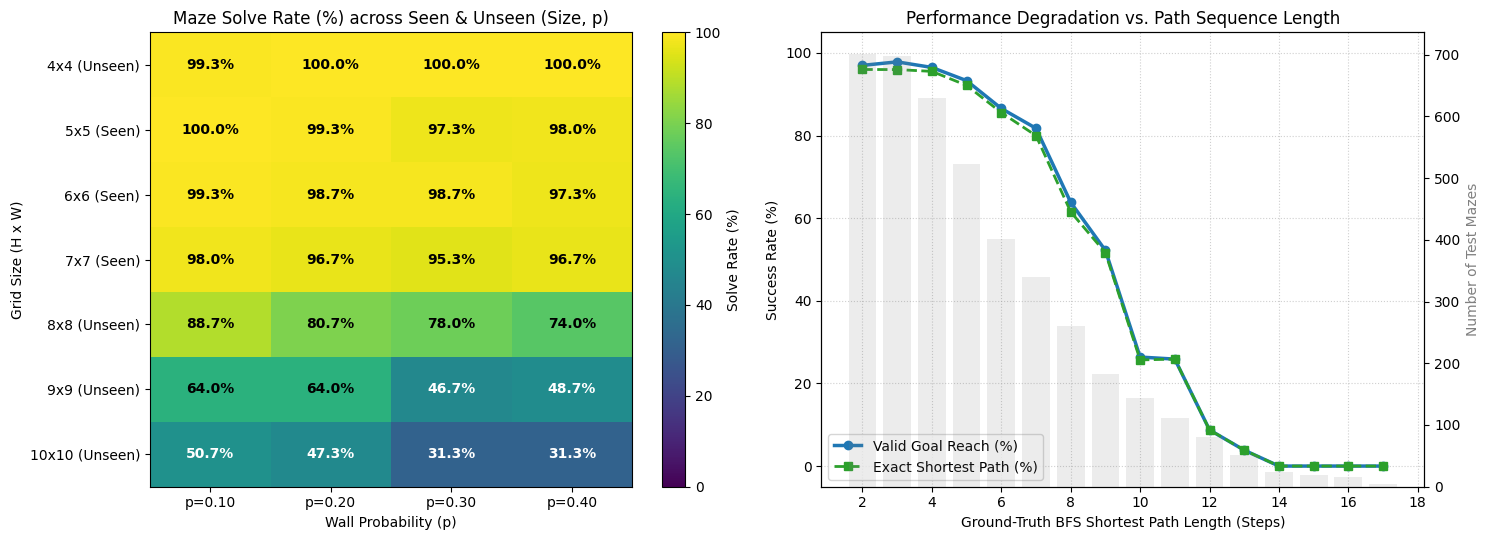

In [4]:
@torch.no_grad()
def evaluate_single_maze(model, grid, start, goal, true_path):
    """
    Autoregressively rolls out the model on a maze of ANY size (H x W)
    and verifies if the predicted trajectory validly reaches the goal.
    """
    model.eval()
    H, W = grid.shape
    max_steps = H * W  # Dynamic upper bound based on current grid size

    grid_tensor = torch.tensor(grid, dtype=torch.long, device=DEVICE).unsqueeze(0)
    memory = model.encode_maze(grid_tensor)

    generated = [ACTION_VOCAB["BOS"]]

    for _ in range(max_steps):
        tgt_seq = torch.tensor([generated], dtype=torch.long, device=DEVICE)
        T = tgt_seq.size(1)

        tgt = model.action_token_emb(tgt_seq) + model._get_1d_sinusoidal_pos(T, DEVICE)
        causal_mask = torch.triu(torch.ones(T, T, device=DEVICE, dtype=torch.bool), diagonal=1)

        out = model.decoder(tgt=tgt, memory=memory, tgt_mask=causal_mask)
        next_token = model.fc_out(out[:, -1, :]).argmax(dim=-1).item()

        if next_token == ACTION_VOCAB["EOS"]:
            break
        generated.append(next_token)

    pred_actions = [IDX_TO_ACTION[idx] for idx in generated[1:]]

    # Simulate agent physics on the H x W grid
    curr_r, curr_c = start
    valid_trace = True
    for act in pred_actions:
        if act not in MOVE_DELTAS:
            valid_trace = False
            break
        dr, dc = MOVE_DELTAS[act]
        nr, nc = curr_r + dr, curr_c + dc
        if 0 <= nr < H and 0 <= nc < W and grid[nr, nc] != MAZE_VOCAB["WALL"]:
            curr_r, curr_c = nr, nc
        else:
            valid_trace = False
            break

    solved = valid_trace and ((curr_r, curr_c) == goal)
    is_optimal = solved and (len(pred_actions) == len(true_path))
    return solved, is_optimal, len(true_path), len(pred_actions)


def benchmark_generalization(
    model,
    test_sizes=[4, 5, 6, 7, 8, 9, 10],       # Includes unseen sizes: 4, 8, 9, 10
    test_wall_probs=[0.10, 0.20, 0.30, 0.40], # Includes unseen wall probabilities
    trials_per_cell=150
):
    """
    Runs a full benchmark over seen & unseen (grid_size, wall_prob) combinations
    and aggregates performance by path sequence length.
    """
    heatmap_solve = np.zeros((len(test_sizes), len(test_wall_probs)))
    length_stats = defaultdict(lambda: {"total": 0, "solved": 0, "optimal": 0})

    print("Running Generalization Benchmark across Seen & Unseen Grid Sizes and Wall Densities...")
    for i, size in enumerate(test_sizes):
        for j, p in enumerate(test_wall_probs):
            solved_count = 0
            for _ in range(trials_per_cell):
                grid, true_path, start, goal = generate_solvable_maze(size=size, wall_prob=p, min_path_len=2)
                solved, is_optimal, true_len, _ = evaluate_single_maze(model, grid, start, goal, true_path)

                if solved:
                    solved_count += 1
                length_stats[true_len]["total"] += 1
                length_stats[true_len]["solved"] += int(solved)
                length_stats[true_len]["optimal"] += int(is_optimal)

            solve_rate = (solved_count / trials_per_cell) * 100
            heatmap_solve[i, j] = solve_rate
            tag = "(SEEN SIZE)" if size in TRAIN_SIZES else "(UNSEEN SIZE)"
            print(f"  Size {size:2d}x{size:<2d} {tag:<13} | p={p:.2f} -> Solve Rate: {solve_rate:5.1f}%")

    # ==========================================
    # Plot 1: 2D Heatmap (Grid Size vs. Wall Prob)
    # ==========================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

    im = ax1.imshow(heatmap_solve, cmap="viridis", vmin=0, vmax=100, aspect="auto")
    ax1.set_xticks(range(len(test_wall_probs)))
    ax1.set_xticklabels([f"p={p:.2f}" for p in test_wall_probs])
    ax1.set_yticks(range(len(test_sizes)))
    ax1.set_yticklabels([
        f"{s}x{s} {'(Seen)' if s in TRAIN_SIZES else '(Unseen)'}" for s in test_sizes
    ])
    ax1.set_xlabel("Wall Probability (p)")
    ax1.set_ylabel("Grid Size (H x W)")
    ax1.set_title("Maze Solve Rate (%) across Seen & Unseen (Size, p)")

    for i in range(len(test_sizes)):
        for j in range(len(test_wall_probs)):
            val = heatmap_solve[i, j]
            color = "black" if val > 55 else "white"
            ax1.text(j, i, f"{val:.1f}%", ha="center", va="center", color=color, fontweight="bold")
    fig.colorbar(im, ax=ax1, label="Solve Rate (%)")

    # ==========================================
    # Plot 2: Accuracy vs. Ground-Truth Path Length
    # ==========================================
    lengths = sorted([L for L, st in length_stats.items() if st["total"] >= 5])
    solve_by_len = [(length_stats[L]["solved"] / length_stats[L]["total"]) * 100 for L in lengths]
    opt_by_len = [(length_stats[L]["optimal"] / length_stats[L]["total"]) * 100 for L in lengths]
    counts = [length_stats[L]["total"] for L in lengths]

    ax2.plot(lengths, solve_by_len, marker="o", linewidth=2.5, color="#1f77b4", label="Valid Goal Reach (%)")
    ax2.plot(lengths, opt_by_len, marker="s", linewidth=2, linestyle="--", color="#2ca02c", label="Exact Shortest Path (%)")
    ax2.set_xlabel("Ground-Truth BFS Shortest Path Length (Steps)")
    ax2.set_ylabel("Success Rate (%)")
    ax2.set_ylim(-5, 105)
    ax2.set_title("Performance Degradation vs. Path Sequence Length")
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(loc="lower left")

    # Annotate sample count on secondary axis
    ax2_sub = ax2.twinx()
    ax2_sub.bar(lengths, counts, alpha=0.15, color="gray", label="Sample Count")
    ax2_sub.set_ylabel("Number of Test Mazes", color="gray")

    plt.tight_layout()
    plt.show()

    return heatmap_solve, length_stats

# Run the comprehensive benchmark!
heatmap_solve, length_stats = benchmark_generalization(model)